In [ ]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 240, done.
remote: Counting objects: 100% (240/240), done.
remote: Compressing objects: 100% (218/218), done.
remote: Total 240 (delta 53), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (240/240), 31.41 MiB | 15.10 MiB/s, done.
Resolving deltas: 100% (53/53), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['buat_dataset_sintetis.py', 'utils_tepi.py', 'praproses.py', 'utils_cv.py', 'bercak.py']


**KODE 1.1**

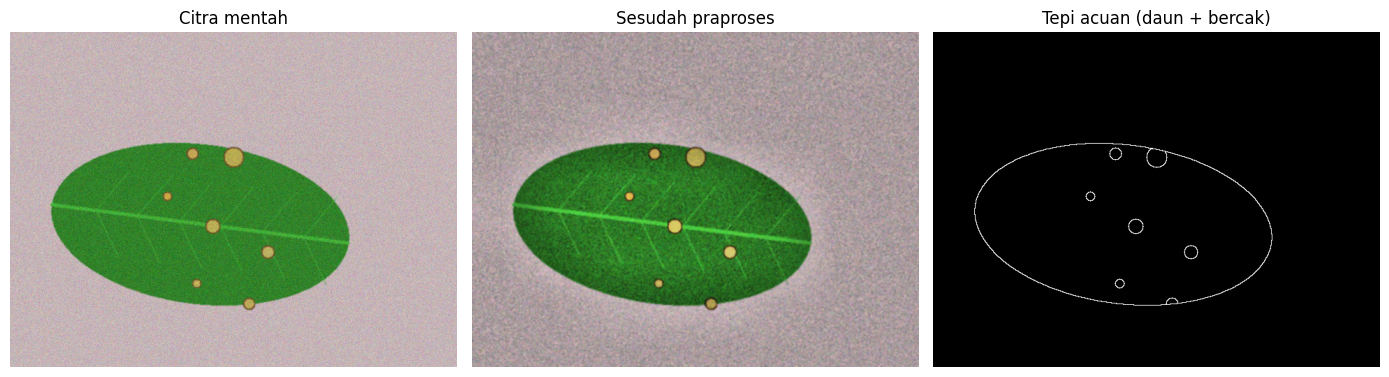

In [ ]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

**KODE 1.2**

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 646.3


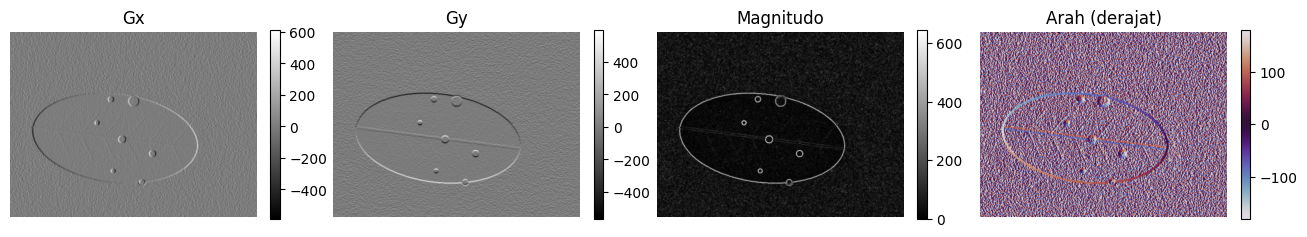

In [ ]:

g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah,
"Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else
"gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)

**KODE 1.3**

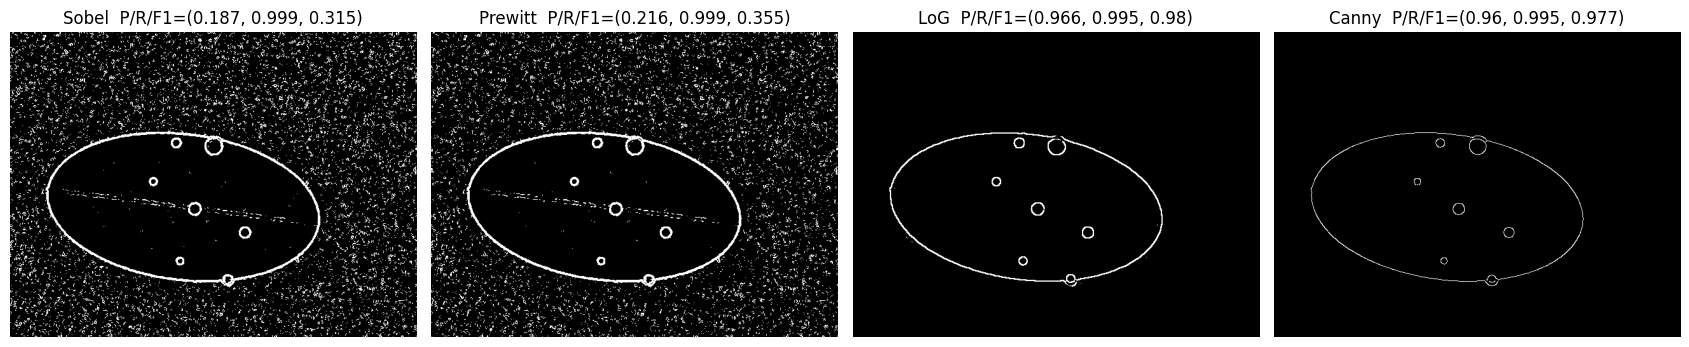

In [ ]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
"Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e
in hasil.items()],
       ukuran=(17, 3.6))

**KODE 1.4**

In [ ]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))

    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [
            ("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
            ("R", im[:, :, 2])
        ]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(
    baris,
    columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"]
)

ringkas = tabel_tepi.groupby(
    ["sumber", "kanal", "metode"]
)[["P", "R", "F1"]].mean().round(3)

print(ringkas)

tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.761  0.752  0.756
                LoG      0.603  0.998  0.745
                Prewitt  0.780  0.957  0.848
                Sobel    0.737  0.965  0.822
          R     Canny    0.985  0.978  0.981
                LoG      0.887  0.997  0.932
                Prewitt  0.527  0.996  0.630
                Sobel    0.469  0.997  0.574
praproses Gray  Canny    0.670  0.951  0.779
                LoG      0.523  0.997  0.677
                Prewitt  0.527  0.997  0.677
                Sobel    0.493  0.997  0.644
          R     Canny    0.945  0.991  0.965
                LoG      0.797  0.998  0.874
                Prewitt  0.439  0.997  0.561
                Sobel    0.402  0.997  0.523


**Grafik batang 1.5**

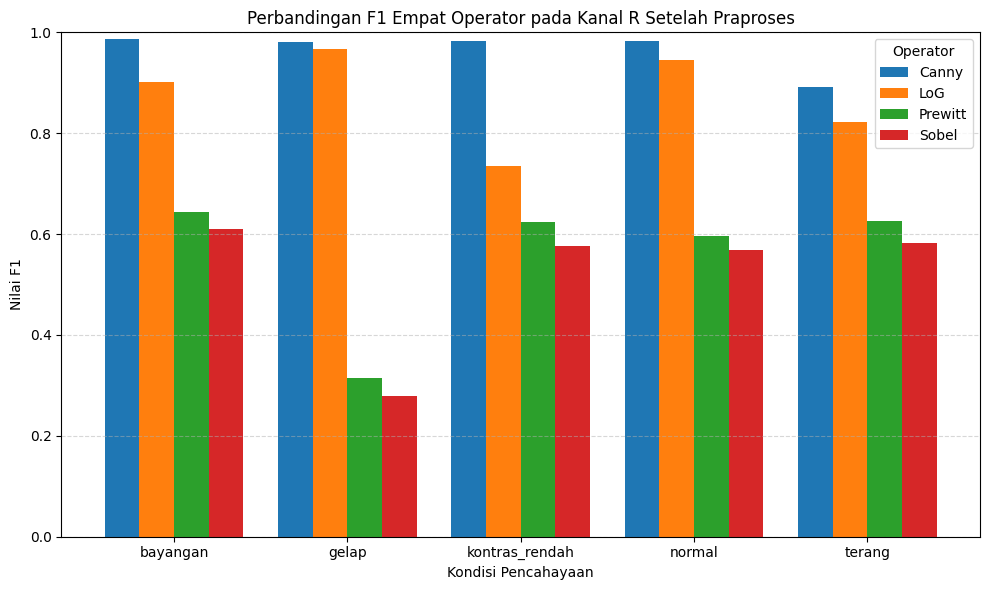

In [ ]:

import matplotlib.pyplot as plt
import os

# Filter data: kanal R dan citra setelah praproses
df_f1 = tabel_tepi[
    (tabel_tepi["sumber"] == "praproses") &
    (tabel_tepi["kanal"] == "R")
]

# Menghitung rata-rata F1 berdasarkan kondisi cahaya dan operator
grafik_f1 = df_f1.pivot_table(
    index="kondisi",
    columns="metode",
    values="F1",
    aggfunc="mean"
)

# Membuat grafik batang
ax = grafik_f1.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Perbandingan F1 Empat Operator pada Kanal R Setelah Praproses")
plt.xlabel("Kondisi Pencahayaan")
plt.ylabel("Nilai F1")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Operator")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Simpan grafik
os.makedirs("../hasil", exist_ok=True)
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=300, bbox_inches="tight")

plt.show()


**KODE 2.1**

In [ ]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]

    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)

    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]  # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])

canny = pd.DataFrame(
    baris,
    columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"]
)

print(
    canny.groupby(["sigma", "ambang"])[
        ["P", "R", "F1", "R_bercak"]
    ].mean().round(3)
)

print(
    canny.pivot_table(
        index=["sigma", "ambang"],
        columns="kelas",
        values="R_bercak"
    ).round(3)
)

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.470  0.994  0.561     0.977
      30/90    0.020  0.997  0.038     0.989
      50/150   0.132  0.995  0.200     0.981
1.0   100/200  0.976  0.994  0.985     0.972
      30/90    0.242  0.994  0.331     0.974
      50/150   0.821  0.994  0.884     0.972
2.0   100/200  0.817  0.792  0.797     0.742
      30/90    0.945  0.991  0.965     0.954
      50/150   0.983  0.982  0.982     0.897
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.979   0.976
      30/90    0.991   0.986
      50/150   0.982   0.979
1.0   100/200  0.976   0.968
      30/90    0.979   0.969
      50/150   0.976   0.969
2.0   100/200  0.755   0.729
      30/90    0.960   0.949
      50/150   0.927   0.867


**KODE 2.2**

In [ ]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x
median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1",
"median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi",
values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.481  0.525           0.779   0.691   0.817
      tetap 30/90     0.744  0.745           0.927   0.736   0.741
R     otomatis        0.448  0.319           0.684   0.702   0.902
      tetap 30/90     0.987  0.981           0.982   0.982   0.892
kanal  kondisi       
Gray   bayangan          119.0
       gelap             136.2
       kontras_rendah    148.6
       normal            168.0
       terang            195.6
R      bayangan          122.9
       gelap             158.4
       kontras_rendah    153.5
       normal            174.5
       terang            197.6
Name: median, dtype: float64


**KODE 2.3**

kanal            Gray      R
kondisi                     
bayangan        642.5    0.0
gelap           882.0    0.0
kontras_rendah   17.0    0.0
normal          852.0  127.8
terang          944.5  272.5


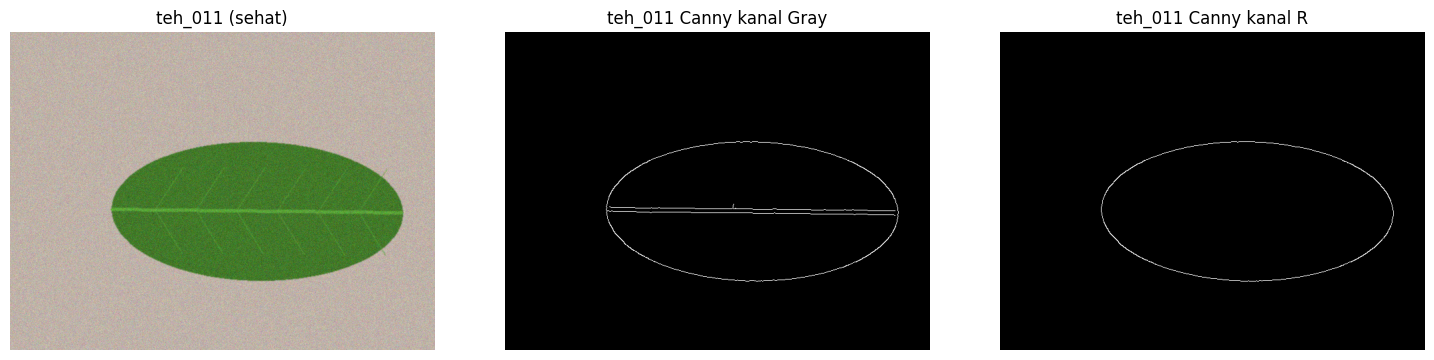

In [ ]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0     # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal",
"piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul,
ukuran=(15, 3.6))